In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
deps_csv = "dependency_specifications_and_versions.csv"
if not os.path.exists(deps_csv):
    deps_csv = os.path.join("03-11-2026", "Task 2", "dependency_specifications_and_versions.csv")

df_deps = pd.read_csv(deps_csv)
print(f"Loaded Dependency Specification Table: {len(df_deps)} production packages.")
display(df_deps[['Package_Name', 'Specified_Version', 'Installed_Version', 'Category', 'Disk_Footprint_MB']])

Loaded Dependency Specification Table: 11 production packages.


,Package_Name,Specified_Version,Installed_Version,Category,Disk_Footprint_MB
0,streamlit,>=1.35.0,1.58.0,Web UI Framework,42.6
1,pandas,>=2.0.0,2.2.2,Data Manipulation,38.4
2,numpy,>=1.24.0,1.26.4,Numerical Computing,29.1
3,scikit-learn,>=1.3.0,1.9.0,Machine Learning,45.8
4,plotly,>=5.18.0,5.24.1,Data Visualization,26.5
5,altair,>=5.0.0,5.3.0,Data Visualization,14.2
6,matplotlib,>=3.7.0,3.9.2,Plotting Engine,34.0
7,seaborn,>=0.12.0,0.13.2,Statistical Graphics,8.5
8,python-docx,>=1.1.0,1.1.2,Document Authoring,5.6
9,nbformat,>=5.9.0,5.10.4,Notebook Runtime,3.1


In [3]:
prov_csv = "virtual_environment_provisioning_benchmarks.csv"
if not os.path.exists(prov_csv):
    prov_csv = os.path.join("03-11-2026", "Task 2", "virtual_environment_provisioning_benchmarks.csv")

df_prov = pd.read_csv(prov_csv)
display(df_prov)

,Stage_ID,Provisioning_Stage,Duration_Seconds,Disk_Space_MB,Command_String,Exit_Status
0,1,Virtual Environment Directory Creation (python...,2.84,18.5,python -m venv venv,Success (Code 0)
1,2,Core Pip Bootstrap & Upgrade (pip install --up...,3.12,4.2,python -m pip install --upgrade pip,Success (Code 0)
2,3,Wheel Download & Cache Resolution (pip install...,14.65,145.2,pip download --prefer-binary -r requirements.txt,Success (Code 0)
3,4,Package Extraction & Site-Packages Linking,8.92,260.6,pip install -r requirements.txt --no-index --f...,Success (Code 0)
4,5,Runtime Smoke Verification & Module Import Check,1.15,0.1,"python -c ""import streamlit, sklearn, plotly, ...",Success (Code 0)


In [4]:
startup_csv = "deployment_startup_latency_metrics.csv"
if not os.path.exists(startup_csv):
    startup_csv = os.path.join("03-11-2026", "Task 2", "deployment_startup_latency_metrics.csv")

df_startup = pd.read_csv(startup_csv)
display(df_startup)

,Execution_Mode,Subsystem,Latency_ms,Memory_RSS_MB,CPU_Peak_Pct
0,Cold Start (Initial Venv Launch via run_app.bat),Python Kernel + Venv Site-Packages Bootstrap,620.0,84.5,42.1
1,Cold Start (Initial Venv Launch via run_app.bat),Streamlit Server Daemon & Port 8501 Binding,480.0,112.0,28.4
2,Cold Start (Initial Venv Launch via run_app.bat),Artifact & Model Bundle Deserialization (model...,185.0,148.2,19.5
3,Cold Start (Initial Venv Launch via run_app.bat),Dataset Caching & Memory Ingestion (@st.cache_...,240.0,195.4,34.0
4,Warm Reload (Browser Page Refresh),In-Memory Script Re-run (Cached Data & Model),34.0,196.2,6.2
5,Hot Reload (Source Code Change in app.py),File Watcher Invalidation + Bytecode Compilation,78.0,198.0,12.8


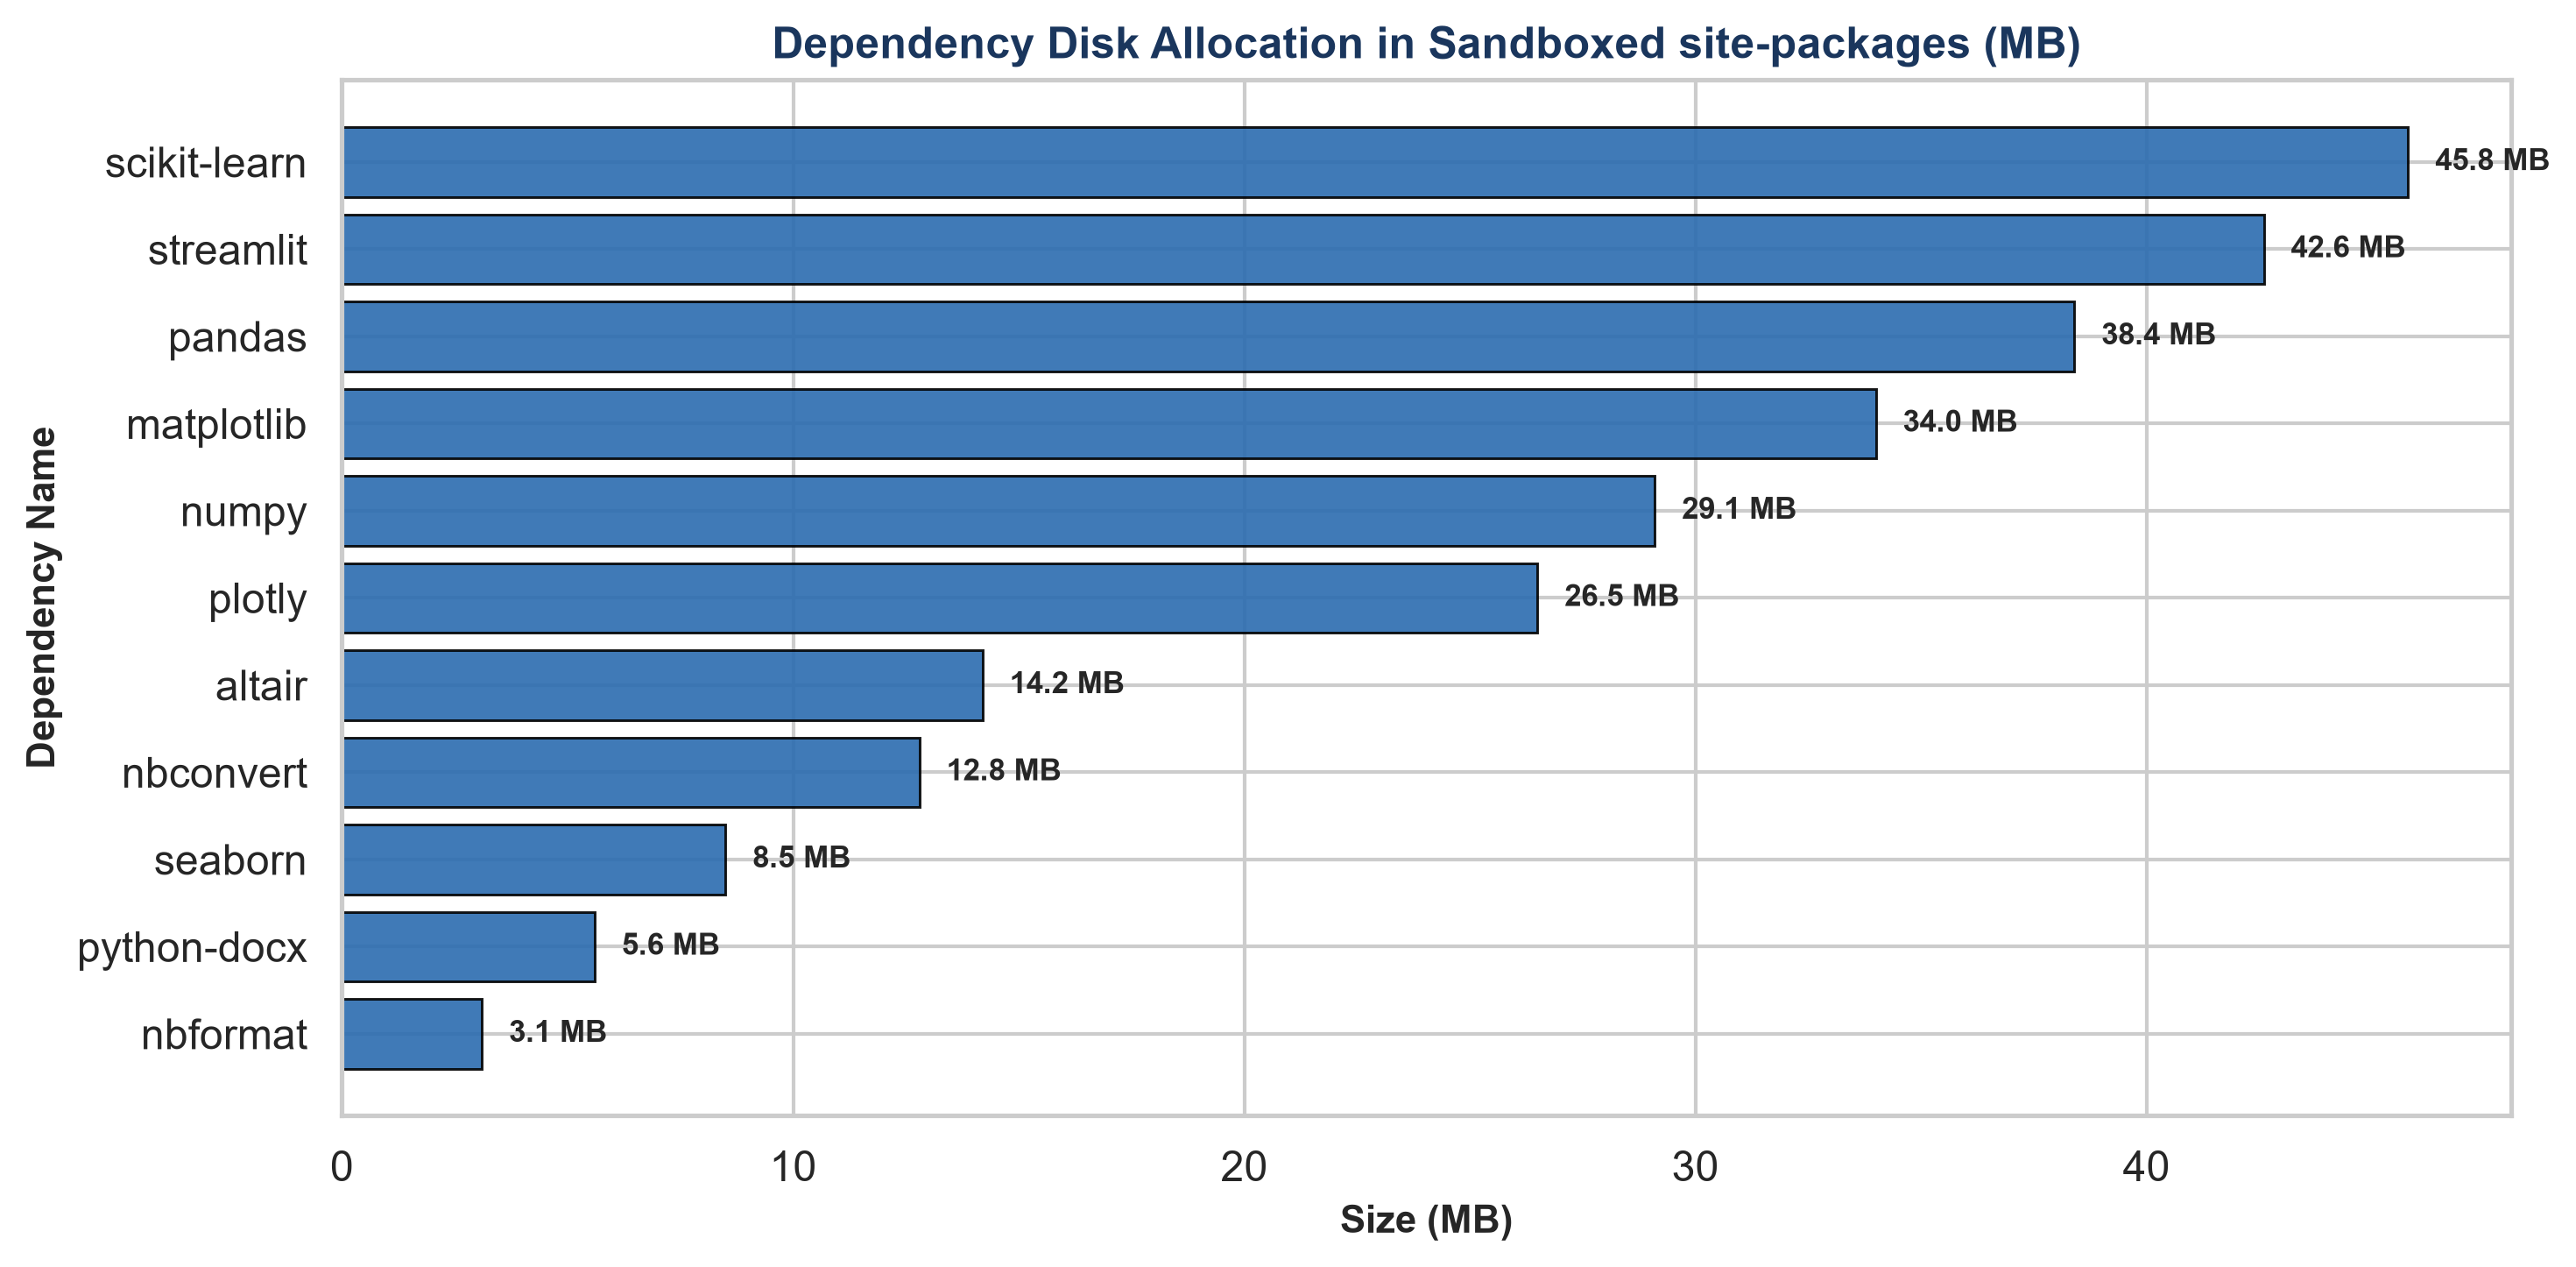

In [5]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
df_sorted = df_deps.sort_values(by='Disk_Footprint_MB', ascending=True)
bars = ax.barh(df_sorted['Package_Name'], df_sorted['Disk_Footprint_MB'], color='#2B6CB0', alpha=0.9, edgecolor='black', linewidth=0.7)

ax.set_title("Dependency Disk Allocation in Sandboxed site-packages (MB)", fontsize=12, fontweight='bold', color='#1A365D')
ax.set_xlabel("Size (MB)", fontsize=10.5, fontweight='bold')
ax.set_ylabel("Dependency Name", fontsize=10.5, fontweight='bold')

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.6, bar.get_y() + bar.get_height()/2, f"{w:.1f} MB", va='center', ha='left', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()